# Proyecto Decision Tree: prediccion de diabetes

Objetivo: predecir `Outcome` (0 = sin diabetes, 1 = con diabetes) con un arbol de decision.

Nota: el conjunto de test no se usa hasta la evaluacion final. Todas las decisiones se toman con validacion cruzada sobre train.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42

df = pd.read_csv("../diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(X_train.shape, X_test.shape)
print("Proporcion de diabetes en train:", round(y_train.mean(), 3))
print("Proporcion de diabetes en test: ", round(y_test.mean(), 3))

(614, 8) (154, 8)
Proporcion de diabetes en train: 0.349
Proporcion de diabetes en test:  0.351


## Bloque 2: EDA sobre train

Los ceros imposibles de Glucose, BloodPressure, SkinThickness, Insulin y BMI se convierten en NaN. Pregnancies se deja igual porque ahi el cero es valido.

In [3]:
COLS_CERO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

def limpiar(X):
    X = X.copy()
    X[COLS_CERO] = X[COLS_CERO].replace(0, np.nan)
    return X

X_train = limpiar(X_train)
X_test = limpiar(X_test)

print(X_train.isna().sum())
print((X_train.isna().mean() * 100).round(1))
X_train.describe().round(2)

Pregnancies                   0
Glucose                       4
BloodPressure                23
SkinThickness               175
Insulin                     290
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
dtype: int64
Pregnancies                  0.0
Glucose                      0.7
BloodPressure                3.7
SkinThickness               28.5
Insulin                     47.2
BMI                          1.5
DiabetesPedigreeFunction     0.0
Age                          0.0
dtype: float64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,614.00,610.00,591.00,439.00,324.00,605.00,614.00,614.00
mean,3.82,121.70,72.15,29.06,149.08,32.45,0.48,33.37
std,3.31,30.10,12.51,10.52,107.23,6.87,0.33,11.83
min,0.00,56.00,24.00,7.00,15.00,18.20,0.08,21.00
25%,1.00,99.00,64.00,21.00,76.00,27.60,0.24,24.00
50%,3.00,117.00,72.00,29.00,125.00,32.40,0.38,29.00
75%,6.00,140.75,80.00,36.00,183.50,36.60,0.64,41.00
max,17.00,199.00,122.00,99.00,744.00,67.10,2.33,81.00


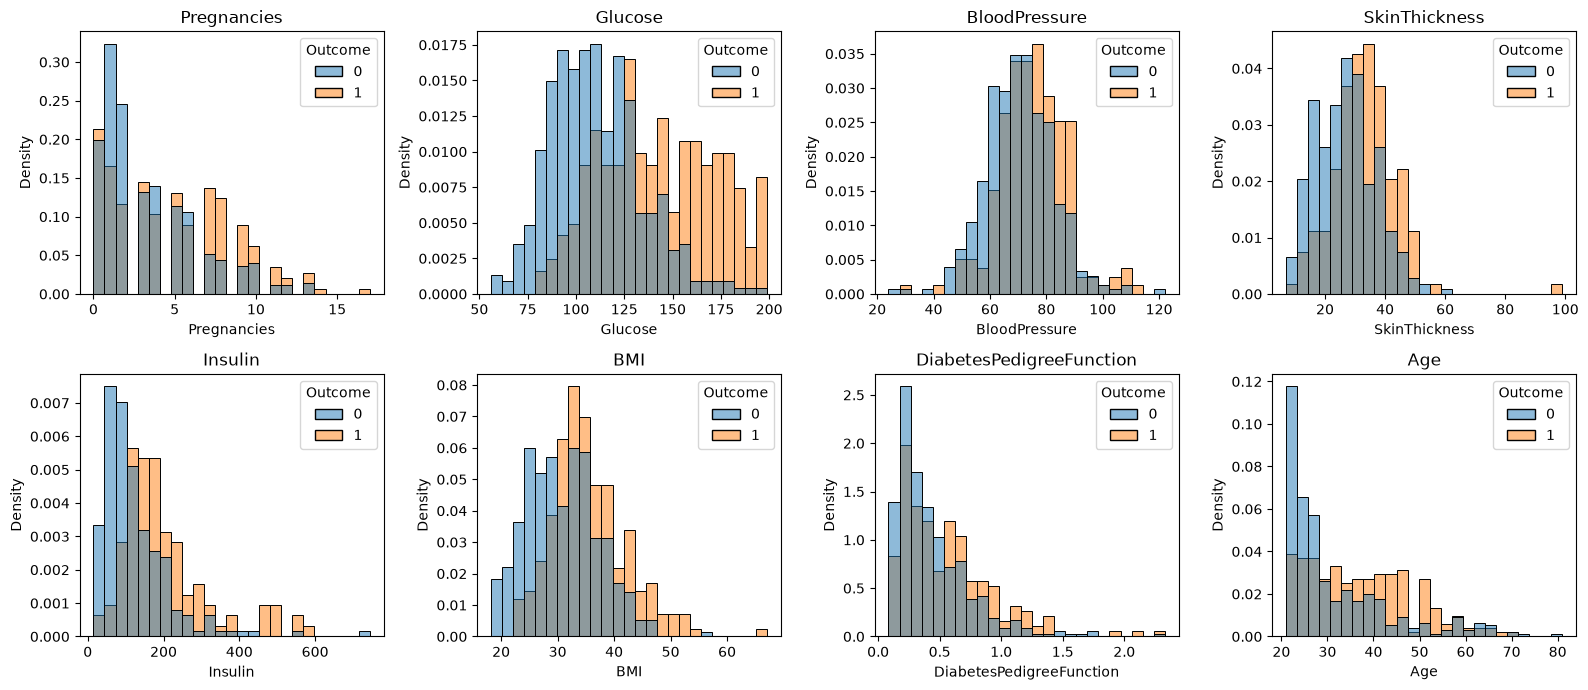

In [4]:
train = X_train.assign(Outcome=y_train)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), X_train.columns):
    sns.histplot(data=train, x=col, hue="Outcome", bins=25,
                 stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

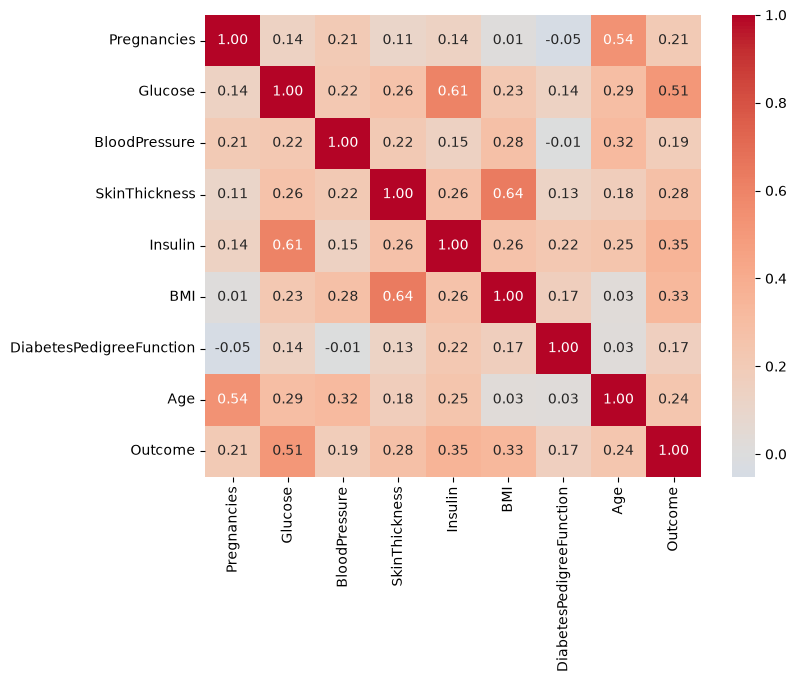

In [5]:
plt.figure(figsize=(8, 6))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

**Conclusiones del bloque 2**

- Faltan muchos datos en dos columnas: Insulin tiene un 47.2% de NaN y SkinThickness un 28.5%. En BloodPressure falta un 3.7%, en BMI un 1.5% y en Glucose un 0.7%.
- Glucose es la variable mas ligada a Outcome (r = 0.51). Le siguen Insulin (0.35), BMI (0.33), SkinThickness (0.28), Age (0.24), Pregnancies (0.21), BloodPressure (0.19) y DiabetesPedigreeFunction (0.17).
- Los diabeticos tienen valores mas altos en todas las variables. La mediana de Glucose es 141.5 frente a 108, la de Age 36 frente a 27 y la de Pregnancies 4 frente a 2.
- Hay asimetria a la derecha en Insulin, Age y DiabetesPedigreeFunction. No hace falta transformarlas, porque un arbol de decision solo usa el orden de los valores.

## Bloques 3 y 4: imputacion y arbol con los tres criterios

La imputacion con la mediana va dentro de un `Pipeline`, de modo que en cada fold se calcula solo con los datos de entrenamiento. Se compara `gini`, `entropy` y `log_loss` con validacion cruzada estratificada de 5 folds.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def modelo(**params):
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("arbol", DecisionTreeClassifier(random_state=SEED, **params)),
    ])

filas = []
for criterio in ["gini", "entropy", "log_loss"]:
    res = cross_validate(modelo(criterion=criterio), X_train, y_train, cv=cv,
                         scoring=["accuracy", "recall"], return_train_score=True)
    filas.append({
        "criterio": criterio,
        "acc_train": res["train_accuracy"].mean(),
        "acc_cv": res["test_accuracy"].mean(),
        "std_acc_cv": res["test_accuracy"].std(),
        "recall_cv": res["test_recall"].mean(),
    })
pd.DataFrame(filas).round(3)

,criterio,acc_train,acc_cv,std_acc_cv,recall_cv
0,gini,1.0,0.673,0.023,0.580
1,entropy,1.0,0.676,0.025,0.543
2,log_loss,1.0,0.676,0.025,0.543


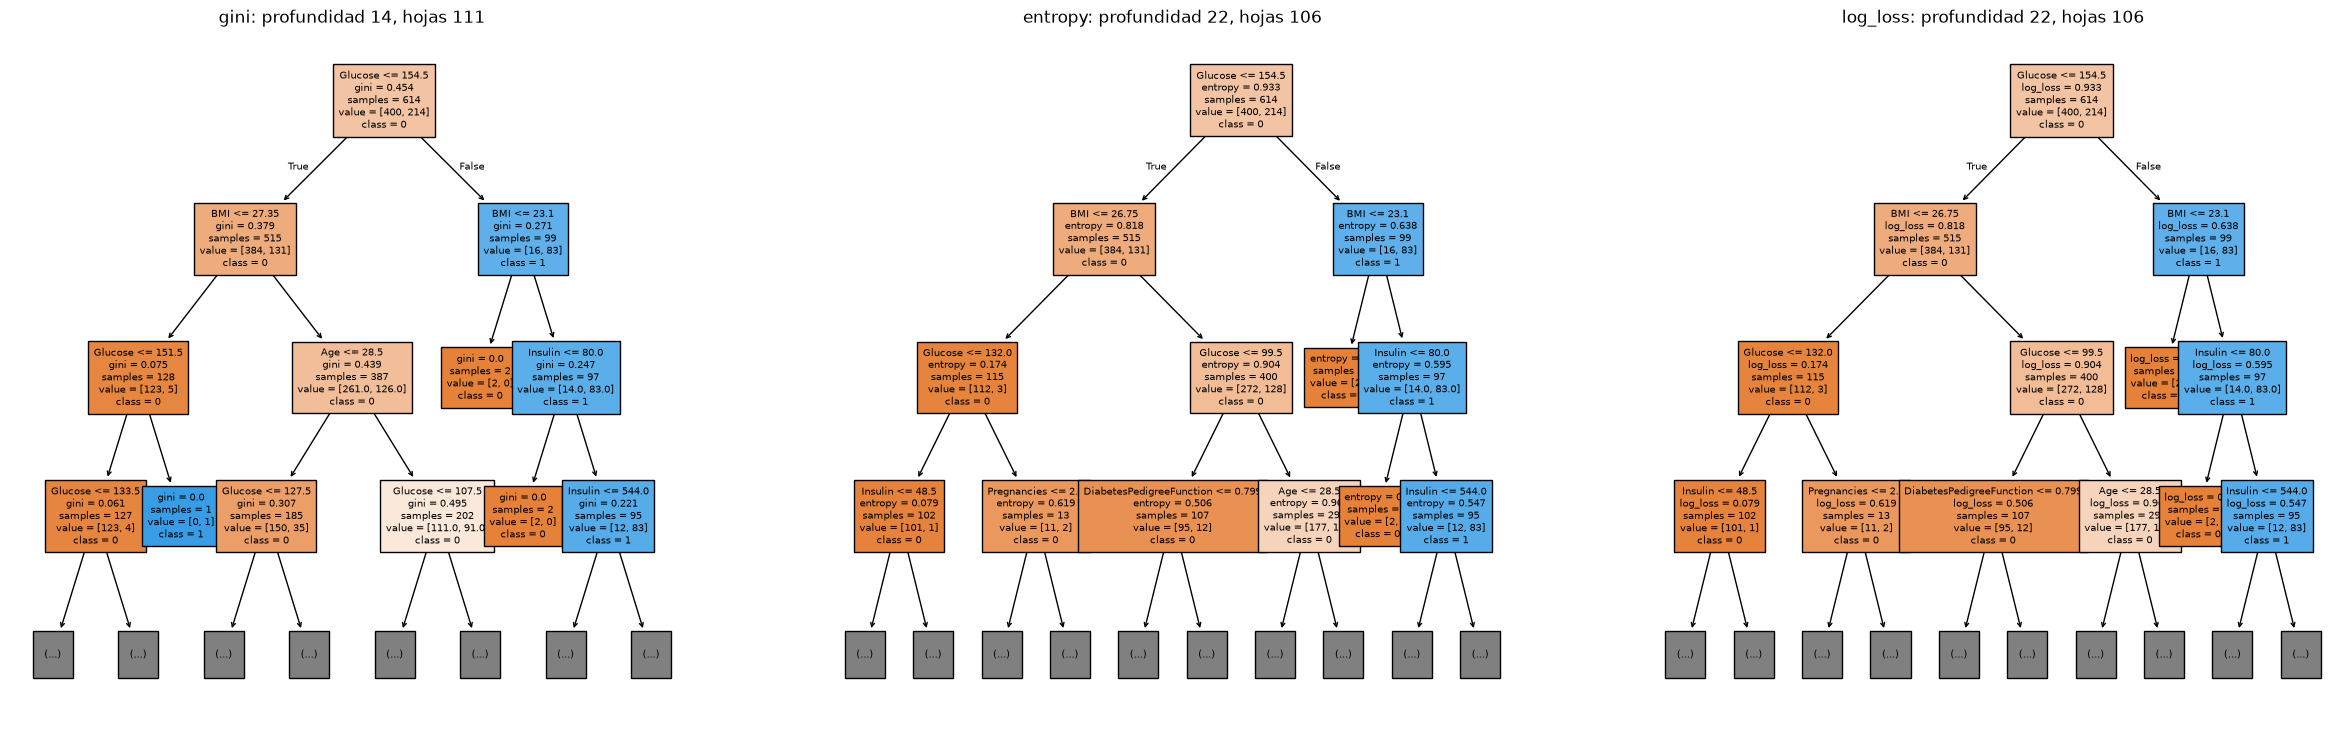

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(30, 9))
for ax, criterio in zip(axes, ["gini", "entropy", "log_loss"]):
    m = modelo(criterion=criterio).fit(X_train, y_train)
    arbol = m.named_steps["arbol"]
    plot_tree(arbol, max_depth=3, feature_names=list(X_train.columns),
              class_names=["0", "1"], filled=True, fontsize=7, ax=ax)
    ax.set_title(f"{criterio}: profundidad {arbol.get_depth()}, hojas {arbol.get_n_leaves()}")
plt.show()

**Conclusiones del bloque 4**

- Los tres criterios dan una accuracy en CV entre 0.673 y 0.676, con desviaciones de 0.023 a 0.025. La diferencia entre ellos es ruido.
- `entropy` y `log_loss` dan resultados identicos porque en scikit-learn calculan la misma entropia.
- `gini` tiene algo mas de recall (0.580 frente a 0.543), una diferencia pequena que no basta para declararlo ganador.
- Sin limites de profundidad el arbol acierta el 100% en train y solo un 67.5% en CV. Memoriza train y apenas supera la linea base de 0.651, que se consigue prediciendo siempre "sin diabetes". Por eso hace falta limitar el arbol.

## Bloque 5: optimizacion de hiperparametros

Como los criterios empatan, `criterion` entra en la rejilla (`gini` y `entropy`; `log_loss` se omite por ser identico a `entropy`). Se optimiza el F1 (equilibrio entre recall y precision) y se muestran tambien la accuracy y el recall. Una primera rejilla optimizando la accuracy elegia hojas de 60 muestras con un recall de 0.527; en un cribado de diabetes no detectar enfermos es lo mas costoso, por eso se pasa a optimizar F1.

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "arbol__criterion": ["gini", "entropy"],
    "arbol__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "arbol__min_samples_split": [2, 10, 20],
    "arbol__min_samples_leaf": [5, 10, 20, 30, 40, 60],
    "arbol__max_features": [None, "sqrt", 0.5],
}

busqueda = GridSearchCV(modelo(), param_grid, cv=cv,
                        scoring=["accuracy", "recall", "f1"], refit="f1",
                        n_jobs=-1, return_train_score=True)
busqueda.fit(X_train, y_train)

i = busqueda.best_index_
print("Mejores parametros:", busqueda.best_params_)
print("F1 CV:         ", round(busqueda.best_score_, 3))
print("Accuracy CV:   ", round(busqueda.cv_results_["mean_test_accuracy"][i], 3))
print("Recall CV:     ", round(busqueda.cv_results_["mean_test_recall"][i], 3))
print("F1 train:     ", round(busqueda.cv_results_["mean_train_f1"][i], 3))

Mejores parametros: {'arbol__criterion': 'gini', 'arbol__max_depth': 6, 'arbol__max_features': 0.5, 'arbol__min_samples_leaf': 30, 'arbol__min_samples_split': 2}
F1 CV:          0.67
Accuracy CV:    0.764
Recall CV:      0.687
F1 train:      0.689


In [9]:
res = pd.DataFrame(busqueda.cv_results_)
cols = ["param_arbol__criterion", "param_arbol__max_depth",
        "param_arbol__min_samples_split", "param_arbol__min_samples_leaf",
        "param_arbol__max_features", "mean_test_accuracy",
        "mean_test_f1", "std_test_f1", "mean_test_recall"]
res.sort_values("rank_test_f1")[cols].head(5).round(3)

,param_arbol__criterion,param_arbol__max_depth,param_arbol__min_samples_split,param_arbol__min_samples_leaf,param_arbol__max_features,mean_test_accuracy,mean_test_f1,std_test_f1,mean_test_recall
317,gini,8,20,30,0.5,0.764,0.67,0.032,0.687
315,gini,8,2,30,0.5,0.764,0.67,0.032,0.687
316,gini,8,10,30,0.5,0.764,0.67,0.032,0.687
262,gini,6,10,30,0.5,0.764,0.67,0.032,0.687
371,gini,10,20,30,0.5,0.764,0.67,0.032,0.687


**Conclusiones del bloque 5**

- Al optimizar F1, la mejor configuracion usa `gini`, hojas de al menos 30 muestras y `max_features=0.5`. Da un F1 de 0.670 en CV, con accuracy 0.764 y recall 0.687.
- Frente a optimizar la accuracy, la accuracy es la misma (0.764), pero el recall sube de 0.527 a 0.687. Se detectan unos 16 diabeticos mas de cada 100 sin perder accuracy.
- El F1 en train (0.689) es casi igual al de CV (0.670), asi que el sobreajuste se ha corregido. El arbol sin limites acertaba el 100% en train.
- Varias configuraciones empatan: profundidad 6, 8 o 10 y `min_samples_split` 2, 10 o 20 dan el mismo resultado. Lo que limita el arbol es `min_samples_leaf=30`, y desde profundidad 6 la profundidad maxima ya no cambia nada.
- `min_samples_leaf=30` queda dentro de la rejilla (de 5 a 60) y no en el borde. La desviacion del F1 entre folds es 0.032, asi que estas estimaciones tienen un margen de error apreciable.

## Bloque 6: arbol final, evaluacion en test y guardado del modelo

El test se usa una sola vez, con el modelo ya elegido por validacion cruzada sobre train. La linea base en test es 0.649 (predecir siempre "sin diabetes").

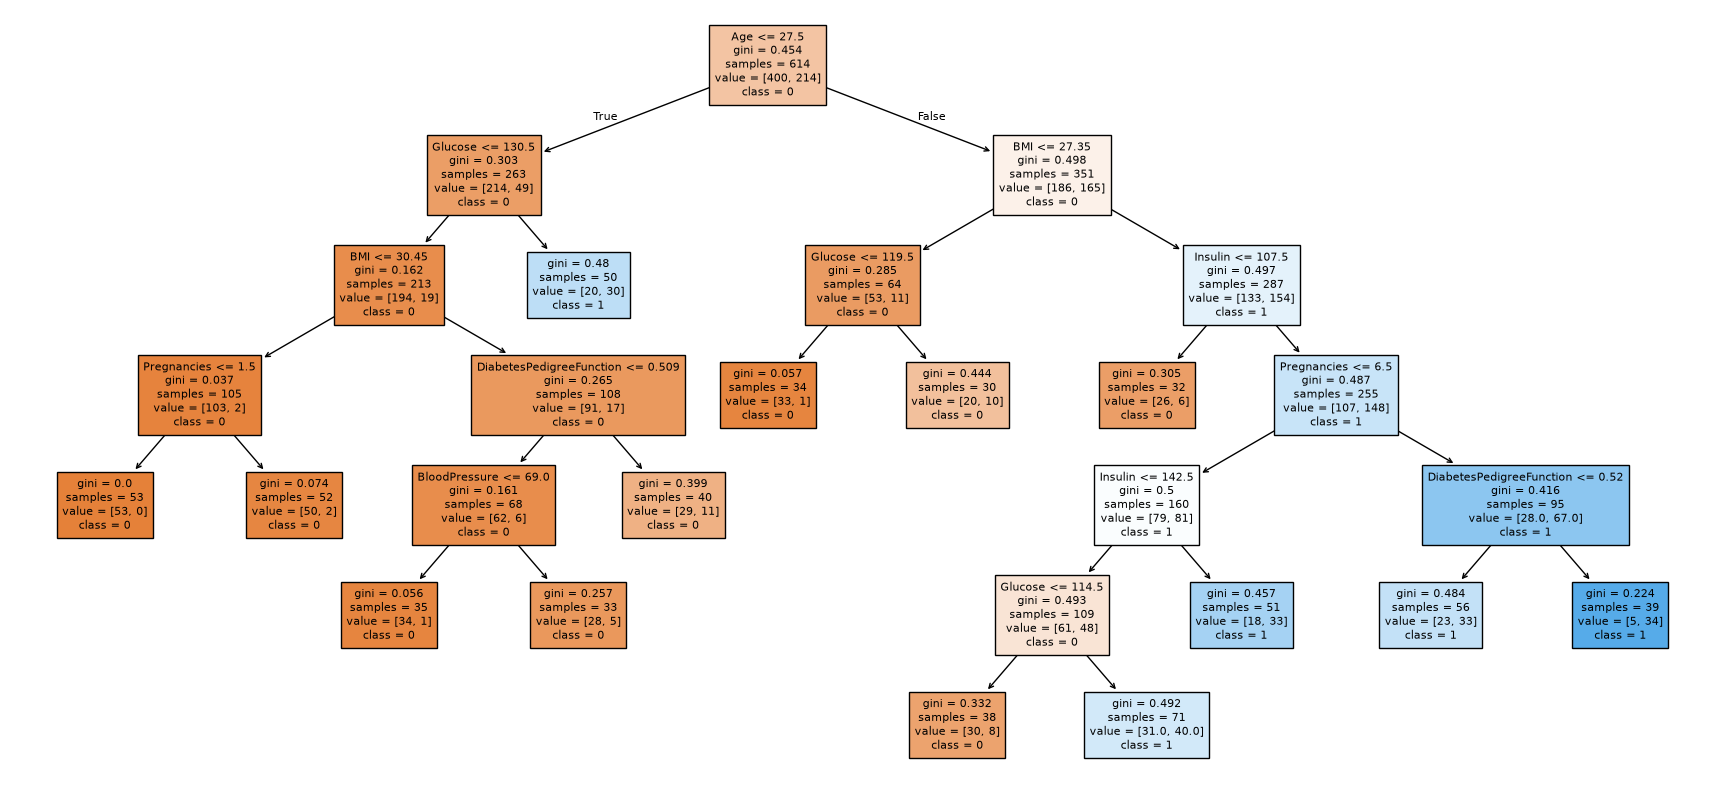

Glucose                     0.326
Age                         0.261
BMI                         0.172
Insulin                     0.126
DiabetesPedigreeFunction    0.058
Pregnancies                 0.052
BloodPressure               0.006
SkinThickness               0.000
dtype: float64


In [10]:
mejor = busqueda.best_estimator_
arbol = mejor.named_steps["arbol"]

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(arbol, feature_names=list(X_train.columns), class_names=["0", "1"],
          filled=True, fontsize=8, ax=ax)
plt.show()

importancias = pd.Series(arbol.feature_importances_, index=X_train.columns)
print(importancias.sort_values(ascending=False).round(3))

Accuracy test:  0.727
Recall test:    0.796
Precision test: 0.581
F1 test:        0.672
Linea base (siempre 0): 0.649


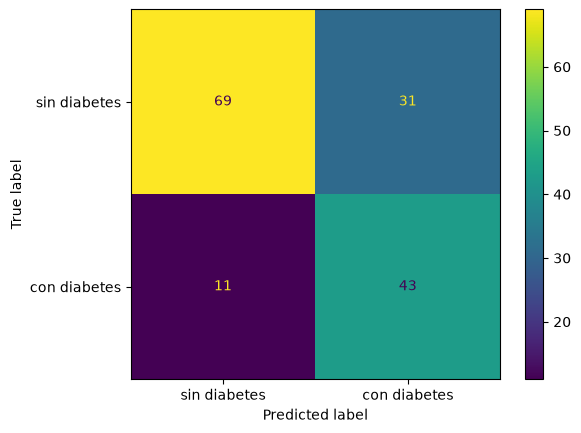

In [11]:
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

pred = mejor.predict(X_test)
print("Accuracy test: ", round(accuracy_score(y_test, pred), 3))
print("Recall test:   ", round(recall_score(y_test, pred), 3))
print("Precision test:", round(precision_score(y_test, pred), 3))
print("F1 test:       ", round(f1_score(y_test, pred), 3))
print("Linea base (siempre 0):", round(1 - y_test.mean(), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["sin diabetes", "con diabetes"]).plot()
plt.show()

In [12]:
import os
import pickle

p = busqueda.best_params_
nombre = (f"arbol_{p['arbol__criterion']}_depth{p['arbol__max_depth']}"
          f"_leaf{p['arbol__min_samples_leaf']}_feat{p['arbol__max_features']}"
          f"_seed{SEED}.pkl")

os.makedirs("../models", exist_ok=True)
with open(f"../models/{nombre}", "wb") as f:
    pickle.dump(mejor, f)
print(nombre)

arbol_gini_depth6_leaf30_feat0.5_seed42.pkl


El archivo guardado contiene el `Pipeline` completo (imputacion con la mediana y arbol). Para predecir con datos nuevos hay que aplicar antes la funcion `limpiar`, que convierte los ceros imposibles en NaN y no forma parte del archivo.

**Conclusiones del bloque 6**

- En test el modelo da accuracy 0.727, recall 0.796, precision 0.581 y F1 0.672. El F1 coincide con el de validacion cruzada (0.670), asi que no hay sobreajuste a la validacion.
- Supera la linea base de test (0.649) en unos 8 puntos de accuracy. La matriz de confusion da 43 diabeticos detectados, 11 sin detectar, 31 falsas alarmas y 69 sanos bien clasificados.
- El modelo prioriza detectar enfermos: recall de 80% a cambio de una precision de 58%, es decir, unas 4 de cada 10 alertas son falsas. Como herramienta de cribado es un compromiso razonable, pero no sirve como diagnostico.
- Glucose es la variable mas importante (0.326), seguida de Age (0.261), BMI (0.172) e Insulin (0.126). BloodPressure y SkinThickness casi no se usan en el arbol.
- El test es pequeno (154 filas, 54 diabeticos): un solo paciente mueve el recall casi dos puntos. La accuracy de test (0.727) queda por debajo de la de CV (0.764), pero dentro de ese margen de error.